In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Exploratory Data Analysis

In [2]:
#Load the Dataset
df = pd.read_csv("Pharma_Industry (1).csv")

df.head()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1


In [3]:
df.shape

(500, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB


In [5]:
df.describe()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.0000
mean,-0.037761,0.214957,0.062871,0.054398,-0.171863,0.5200
std,0.979891,1.247567,0.971978,0.986001,0.983765,0.5001
min,-3.019512,-3.773897,-2.940389,-3.401277,-3.110431,0.0000
25%,-0.642003,-0.565168,-0.648157,-0.586085,-0.797715,0.0000
50%,-0.019340,0.201532,0.027732,-0.065661,-0.108106,1.0000
75%,0.641151,0.951375,0.710774,0.633914,0.513555,1.0000
max,2.949094,4.111751,3.193108,3.373269,2.518023,1.0000


In [6]:
df.isnull().sum()

Drug Dosage (mg)                  0
Systolic Blood Pressure (mmHg)    0
Heart Rate (BPM)                  0
Liver Toxicity Index (U/L)        0
Blood Glucose Level (mg/dL)       0
Drug Response                     0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

Drug Dosage (mg)                  float64
Systolic Blood Pressure (mmHg)    float64
Heart Rate (BPM)                  float64
Liver Toxicity Index (U/L)        float64
Blood Glucose Level (mg/dL)       float64
Drug Response                       int64
dtype: object

In [10]:
df['Drug Response'].value_counts()

Drug Response
1    260
0    240
Name: count, dtype: int64

In [11]:
 df['Drug Response'].value_counts(normalize=True) * 100

Drug Response
1    52.0
0    48.0
Name: proportion, dtype: float64

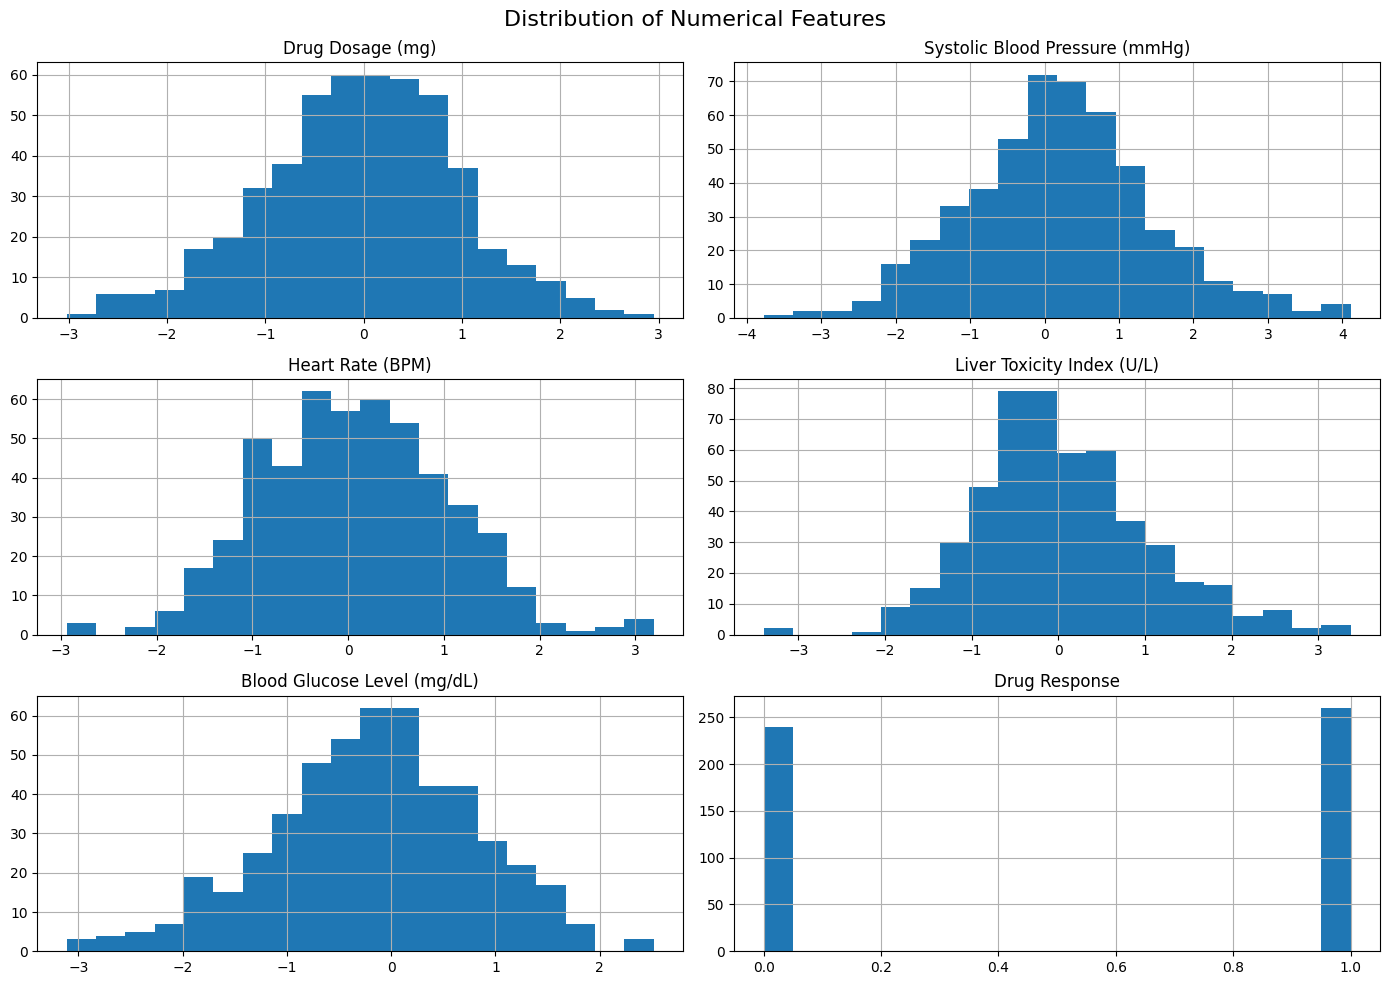

In [12]:
#histogram
df.hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

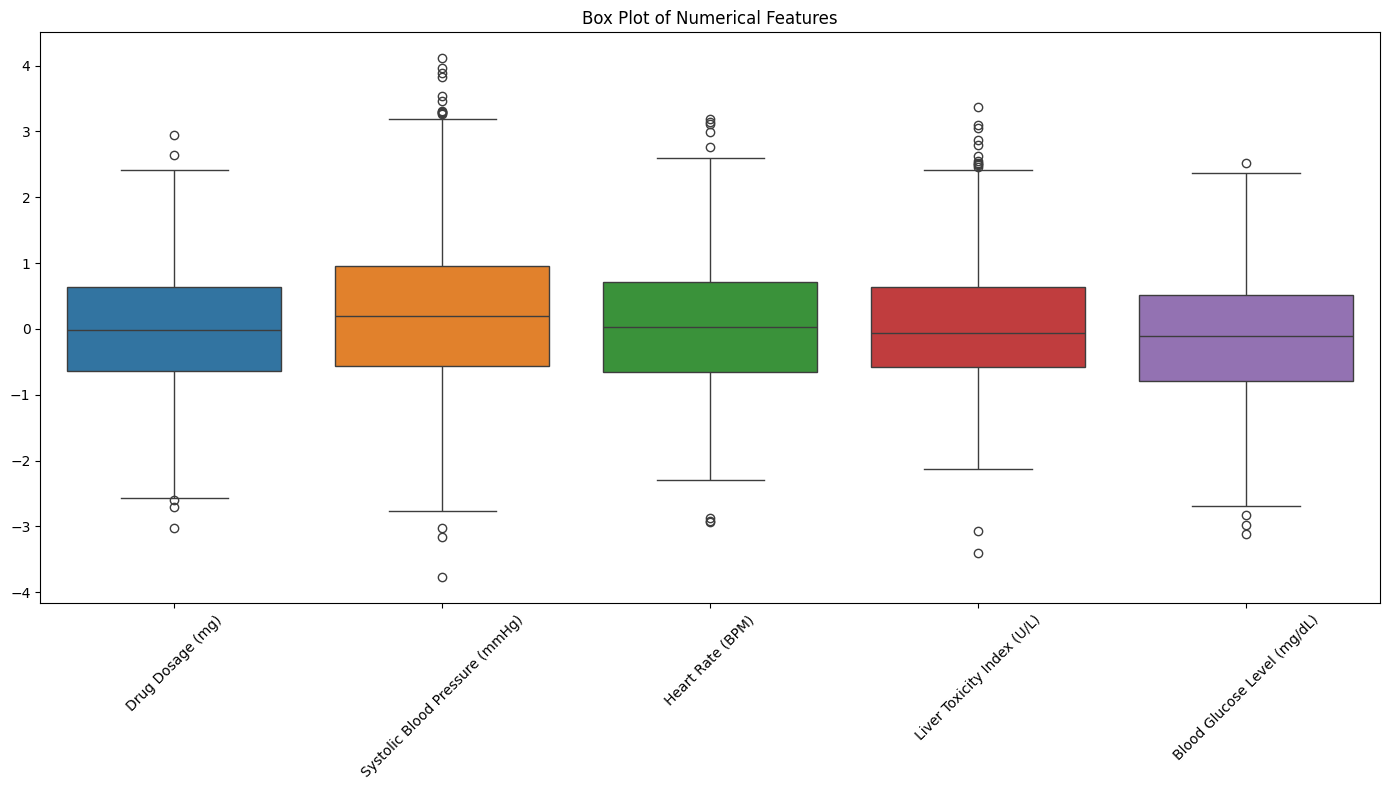

In [13]:
#boxplot
numeric_features = [
    'Drug Dosage (mg)',
    'Systolic Blood Pressure (mmHg)',
    'Heart Rate (BPM)',
    'Liver Toxicity Index (U/L)',
    'Blood Glucose Level (mg/dL)'
]

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df[numeric_features]
)

plt.xticks(rotation=45)
plt.title("Box Plot of Numerical Features")
plt.tight_layout()
plt.show()

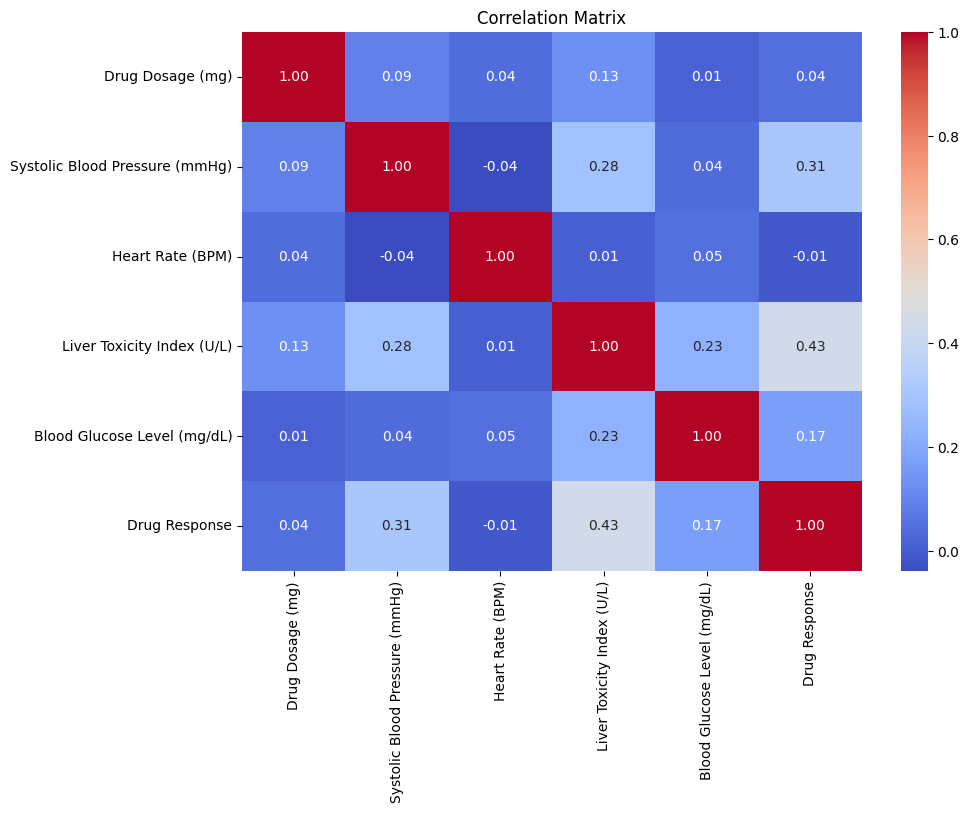

In [14]:
#feature correlation
correlation_matrix = df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")

plt.show()

# Data Preprocessing

In [15]:
#All five input features are numerical
# No categorical encoding is required

In [16]:
X = df.drop('Drug Response', axis=1)

y = df['Drug Response']

In [17]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (500, 5)
y shape: (500,)


In [18]:
#Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 5)
Testing data: (100, 5)


In [19]:
#Feature Scaling
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf'))
])

# Data Visualization

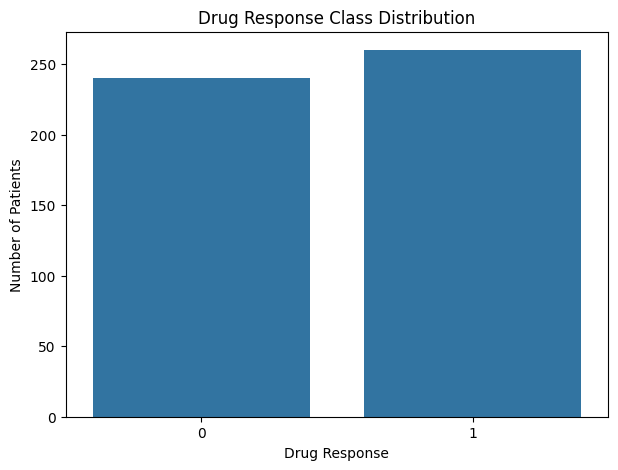

In [20]:
#Class Distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x='Drug Response',
    data=df
)

plt.title("Drug Response Class Distribution")
plt.xlabel("Drug Response")
plt.ylabel("Number of Patients")

plt.show()

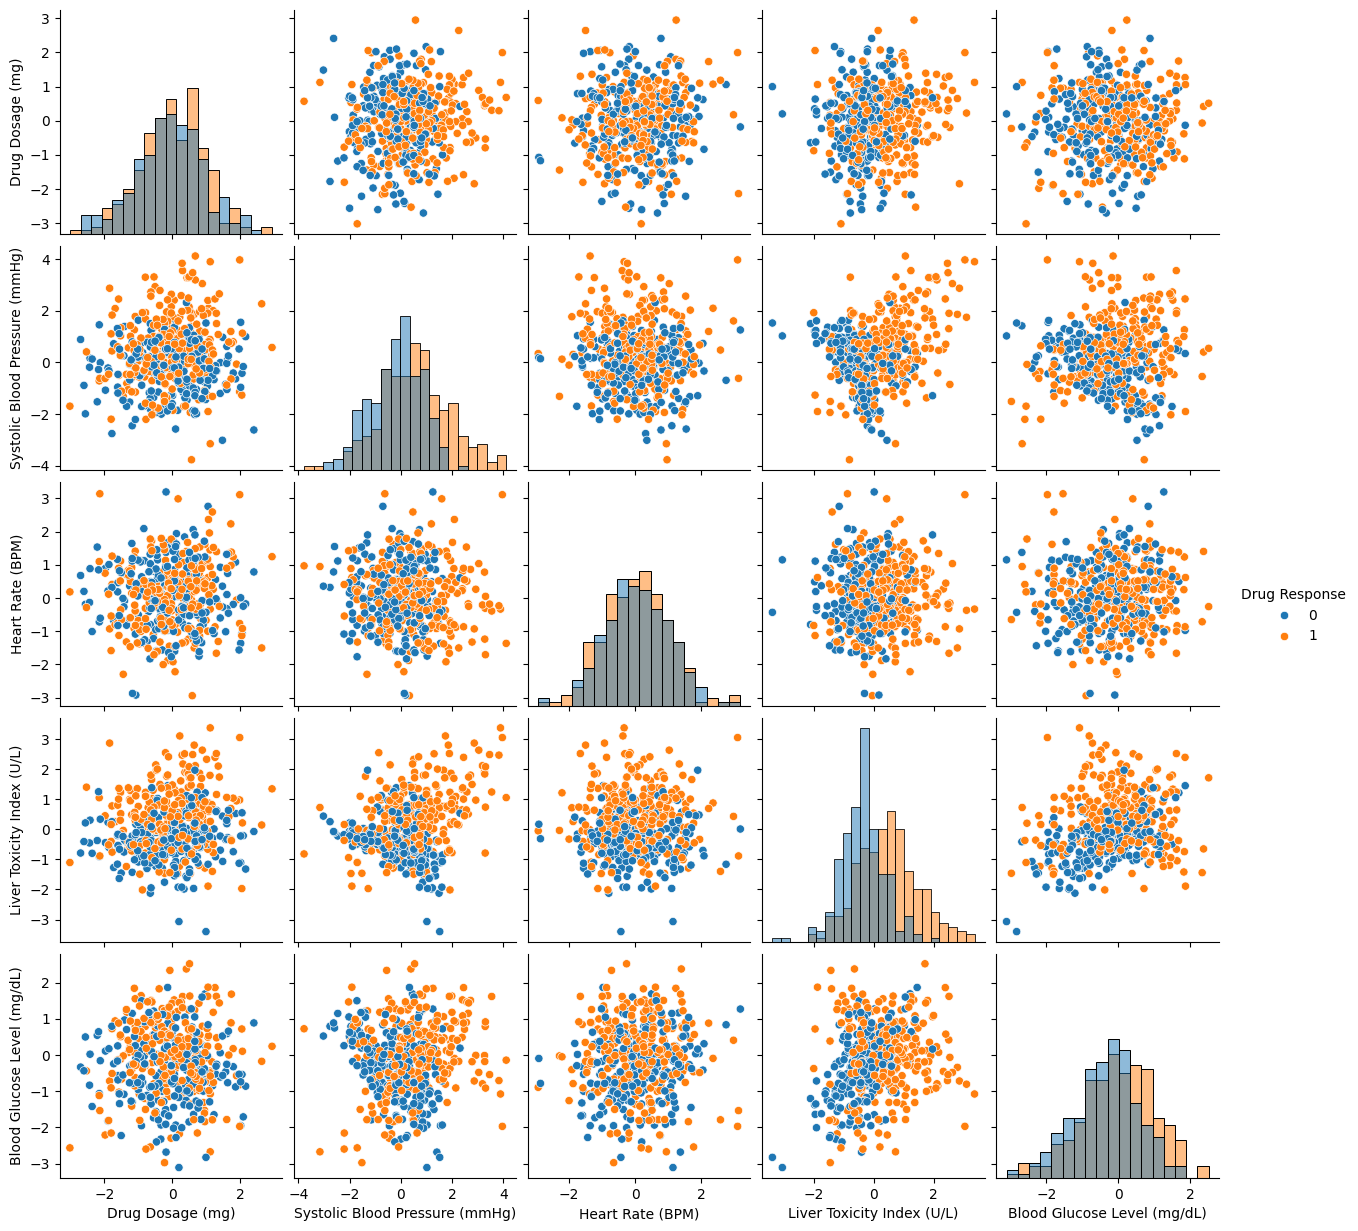

In [21]:
#Pair Plot
sns.pairplot(
    df,
    hue='Drug Response',
    diag_kind='hist'
)

plt.show()

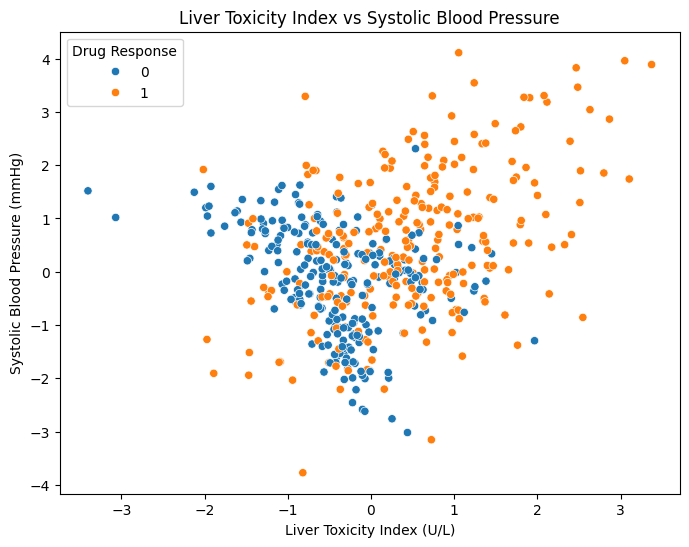

In [22]:
#Scatter Plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Liver Toxicity Index (U/L)',
    y='Systolic Blood Pressure (mmHg)',
    hue='Drug Response'
)

plt.title(
    "Liver Toxicity Index vs Systolic Blood Pressure"
)

plt.show()

# SVM Implementation

In [23]:
#Basic SVM Classifier
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale'
    ))
])

In [24]:
#Train the Model
svm_model.fit(
    X_train,
    y_train
)

,steps,"[('scaler', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'


In [26]:
y_pred = svm_model.predict(X_test)

In [28]:
#Evaluate the Model
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

precision = precision_score(
    y_test,
    y_pred
)

print("Precision:", precision)

recall = recall_score(
    y_test,
    y_pred
)

print("Recall:", recall)

f1 = f1_score(
    y_test,
    y_pred
)

print("F1 Score:", f1)

Accuracy: 0.77
Precision: 0.7543859649122807
Recall: 0.8269230769230769
F1 Score: 0.7889908256880734


In [29]:
#Classification Report
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.79      0.71      0.75        48
           1       0.75      0.83      0.79        52

    accuracy                           0.77       100
   macro avg       0.77      0.77      0.77       100
weighted avg       0.77      0.77      0.77       100



# Visualization of SVM Results

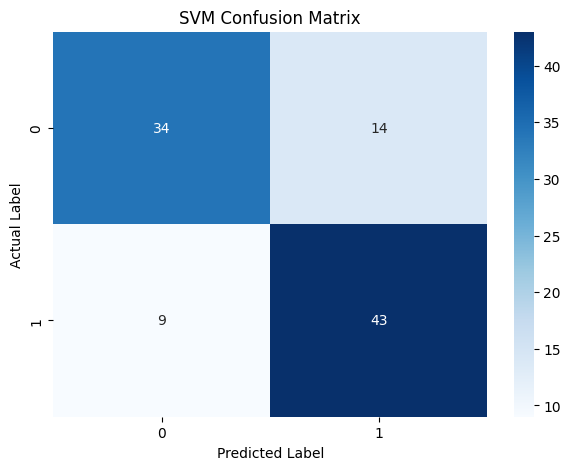

In [30]:
#Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("SVM Confusion Matrix")

plt.show()

In [31]:
from sklearn.decomposition import PCA

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(
    X_train_scaled
)

X_test_pca = pca.transform(
    X_test_scaled
)

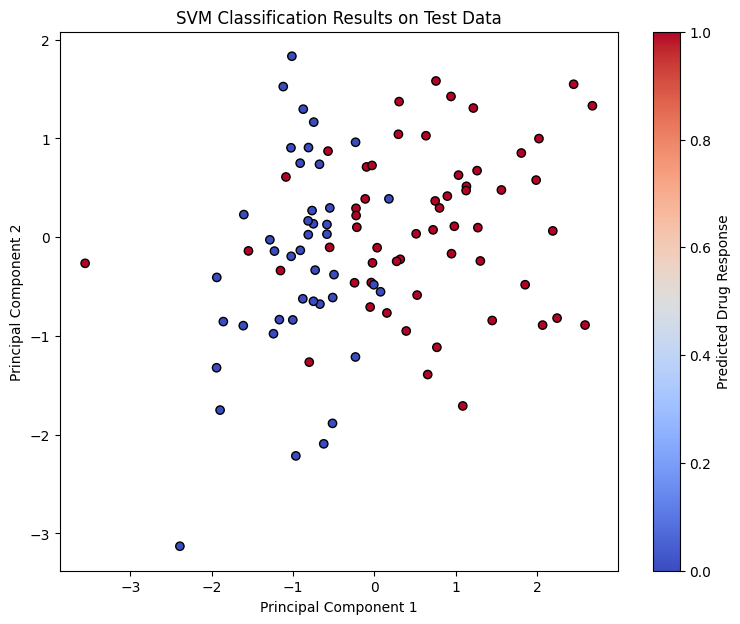

In [32]:
plt.figure(figsize=(9, 7))

scatter = plt.scatter(
    X_test_pca[:, 0],
    X_test_pca[:, 1],
    c=y_pred,
    cmap='coolwarm',
    edgecolor='k'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "SVM Classification Results on Test Data"
)

plt.colorbar(
    scatter,
    label="Predicted Drug Response"
)

plt.show()

# Parameter Tuning and Optimization 

In [37]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

In [38]:
param_grid = {
    'svm__kernel': [
        'linear',
        'poly',
        'rbf'
    ],

    'svm__C': [
        0.1,
        1,
        10,
        100
    ],

    'svm__gamma': [
        'scale',
        'auto',
        0.01,
        0.1,
        1
    ]
}

In [39]:
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(
    X_train,
    y_train
)

,estimator,"Pipeline(step...svm', SVC())])"
,param_grid,"{'svm__C': [0.1, 1, ...], 'svm__gamma': ['scale', 'auto', ...], 'svm__kernel': ['linear', 'poly', ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [40]:
#best parameters
print(
    "Best Parameters:"
)

print(
    grid_search.best_params_
)

Best Parameters:
{'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': 'rbf'}


In [41]:
print(
    "Best CV F1 Score:",
    grid_search.best_score_
)

Best CV F1 Score: 0.7697309248381219


In [42]:
#Evaluate Tuned Model
best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(
    X_test
)

In [43]:
print(
    classification_report(
        y_test,
        tuned_predictions
    )
)

              precision    recall  f1-score   support

           0       0.73      0.67      0.70        48
           1       0.71      0.77      0.74        52

    accuracy                           0.72       100
   macro avg       0.72      0.72      0.72       100
weighted avg       0.72      0.72      0.72       100



# Comparison and Analysis

In [44]:
#Train Linear, Polynomial and RBF SVM
kernels = [
    'linear',
    'poly',
    'rbf'
]

results = []

for kernel in kernels:

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(
            kernel=kernel,
            C=1.0,
            gamma='scale'
        ))
    ])

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy_score(
            y_test,
            predictions
        ),
        'Precision': precision_score(
            y_test,
            predictions
        ),
        'Recall': recall_score(
            y_test,
            predictions
        ),
        'F1 Score': f1_score(
            y_test,
            predictions
        )
    })

results_df = pd.DataFrame(results)

results_df

,Kernel,Accuracy,Precision,Recall,F1 Score
0,linear,0.72,0.760870,0.673077,0.714286
1,poly,0.65,0.666667,0.653846,0.660194
2,rbf,0.77,0.754386,0.826923,0.788991


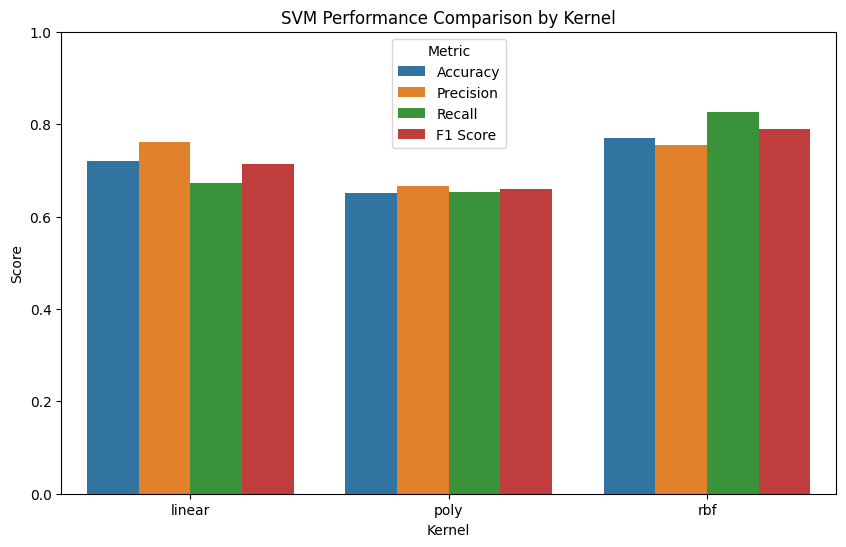

In [45]:
#Visualize Kernel Comparison
results_melted = results_df.melt(
    id_vars='Kernel',
    value_vars=[
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_melted,
    x='Kernel',
    y='Score',
    hue='Metric'
)

plt.ylim(0, 1)

plt.title(
    "SVM Performance Comparison by Kernel"
)

plt.show()

#### Analysis of the Three Kernels

SVM

Strengths

1. Works with numerical features

The dataset contains five numerical predictor variables, so SVM can be applied without categorical encoding.

2. Can model nonlinear relationships

The RBF kernel allows SVM to capture relationships that a simple linear classifier may not capture.

3. Suitable for moderate-sized datasets

Your dataset has 500 observations, which is a relatively small dataset for SVM training.

4. Scaling is straightforward

Standardization can place the features on comparable scales before SVM training.

Weaknesses
1. Sensitive to hyperparameters

        C
        gamma
        kernel

3. Sensitive to feature scaling

Using unscaled variables can cause features with larger numerical ranges to have disproportionate influence.

3. Interpretation

SVM decision functions, particularly with nonlinear kernels, can be more difficult to interpret than simple linear models.

4. Dataset validation

A model achieving a particular test score on this dataset does not establish clinical effectiveness. Real-world healthcare use would require appropriate external validation, clinical evaluation, and consideration of data quality and patient safety

#### Practical Implications
SVM can be useful for classification problems where the relationship between input variables and the target may be nonlinear. In drug response classification, variables such as drug dosage, blood pressure, heart rate, liver toxicity and blood glucose can be used as predictive features. The RBF kernel provides flexibility for modeling nonlinear patterns. However, model performance depends on appropriate preprocessing, feature scaling and hyperparameter tuning. In practical healthcare applications, an SVM model should be evaluated using sufficiently representative data and appropriate validation before being considered for clinical decision-making.